# Nesting a Regional Ocean Model — Caribbean Sea Example

This notebook demonstrates MOM6-in-CESM **domain nesting**: running progressively finer child domains whose open-boundary conditions (OBCs) come from the next coarser parent, rather than from a global reanalysis like GLORYS.

Nesting lets you zoom into a turbulent feature at a fraction of the cost of running the full coarse domain at high resolution.

---

## Domain hierarchy

```
Parent       (carib12)     1/12°    -98.5→-35.5 lon, -6→32 lat
│  4× refinement
└── Middle child           1/48°    -73.5→-62.5 lon,  10→18 lat
    │  4× refinement
    └── Tiny child         1/192°   -70.5→-66.5 lon,  12→16 lat   ← smallest, highest res
```

**Rule of thumb**: each child should be no more than 4× finer than its parent (4:1 ratio).
Here: 1/12° → 1/48° = 4× refinement; 1/48° → 1/192° = 4× refinement — both right at the max
recommended ratio. Note the extents were kept the same size as the original 1/24°/1/48° setup
(just shifted 2.5° east), so at 1/192° the tiny child is a much bigger grid (768×768 pts) than
a typically "tiny" nested domain — shrink `lenx`/`leny` in Step 2 if you want to bring the point
count back down.

---

## Workflow

The three domains are built up **together, step by step**, rather than one domain at a time — each step below does the same thing for the parent and both children, since the calls are basically identical across domains:

1. **Paths** — case/input paths and reference files for all three domains
2. **Grids** — horizontal grid for the parent (loaded from a reference supergrid) and both children (created fresh) — includes a grid-only visualization (no bathymetry) to sanity-check footprints before the expensive steps
3. **Topography** — bathymetry for the parent (loaded from a reference file) and both children (from GEBCO)
4. **Vertical grids** — parent (loaded from a reference file) and both children (hyperbolic)
5. **CESM cases** — create all three cases
6. **Forcings** — configure OBCs for all three: parent from GLORYS/reference OBC files, children from `CESM_MOM_OUTPUT.get_mom6_output_data()` reading their parent's nesting output


## Setup — imports

In [1]:
%load_ext autoreload
%autoreload 2
from pathlib import Path
from CrocoDash.grid import Grid
from CrocoDash.topo import Topo
from CrocoDash.vgrid import VGrid
from CrocoDash.case import Case


## Step 1 — Paths and reference files (parent, middle child, tiny child)

In [2]:
CESMROOT = Path("~/work/installs/CROCESM_workshop_2025").expanduser()
PROJECT  = "ncgd0011"
GEBCO    = Path("/glade/derecho/scratch/manishrv/ice/croc/gebco/GEBCO_2024.nc")

# --- Parent (carib12) ---
PARENT_CASE  = Path("~/croc_cases/carib12_nesting_demo").expanduser()
PARENT_INPUT = Path("/glade/u/home/manishrv/scratch/croc_input/carib12_nesting_demo")

# Reference case files from Ajanney's carib12 run
REF_INPUT     = Path("/glade/work/ajanney/CrocoDash_Input/carib12_credit_tides_runoff_02/ocnice")
REF_SUPERGRID = REF_INPUT / "ocean_hgrid_carib_012_hgrid_df37c4.nc"
REF_TOPOG     = REF_INPUT / "ocean_topog_carib_012_hgrid_df37c4.nc"
REF_VGRID     = REF_INPUT / "vgrid_65L_20200626.nc"

# --- Middle child (1/24°, eastern Caribbean) ---
MID_CASE  = Path("~/croc_cases/carib_mid_child").expanduser()
MID_INPUT = Path("/glade/u/home/manishrv/scratch/croc_input/carib_mid_child")

# --- Tiny child (1/48°, southern Caribbean) ---
TINY_CASE  = Path("~/croc_cases/carib_tiny_child").expanduser()
TINY_INPUT = Path("/glade/u/home/manishrv/scratch/croc_input/carib_tiny_child")

# --- Nesting sources (each child's OBC comes from the next coarser domain's own MOM6 output) ---
PARENT_NESTING_OUTPUT = Path("~/scratch/archive/carib12_nesting_demo/ocn/hist/nesting_files").expanduser()
MID_NESTING_OUTPUT    = Path("~/scratch/archive/carib_mid_child/ocn/hist/nesting_files").expanduser()


## Step 2 — Horizontal grids (parent, middle child, tiny child)

In [3]:
# Parent — load the existing carib12 supergrid directly, no need to re-generate
parent_grid = Grid.from_supergrid(REF_SUPERGRID, name="carib12_nesting_demo")

# Middle child — 1/48°, 4x refinement over the 1/12° parent
# shifted 2.5° east of the original placement
mid_grid = Grid(
    resolution = 1/48,
    xstart     = -73.5,
    lenx       = 11.0,   # -73.5 → -62.5
    ystart     = 10.0,
    leny       = 8.0,    # 10 → 18
    name       = "carib_mid_child",
)

# Tiny child — 1/192°, 4x refinement over the 1/48° middle child
# shifted 2.5° east of the original placement
tiny_grid = Grid(
    resolution = 1/192,
    xstart     = -70.5,
    lenx       = 4.0,    # -70.5 → -66.5
    ystart     = 12.0,
    leny       = 4.0,    # 12 → 16
    name       = "carib_tiny_child",
)

print(f"Parent grid: {parent_grid}")
print(f"Middle child grid: {mid_grid}")
print(f"Tiny child grid: {tiny_grid}")


Parent grid: <mom6_forge.grid.Grid object at 0x7ff4bbab1350>
Middle child grid: <mom6_forge.grid.Grid object at 0x7ff4baa6d7d0>
Tiny child grid: <mom6_forge.grid.Grid object at 0x7ff504c822d0>


### Grid check — visualize the nested footprints before generating bathymetry

Before paying the cost of regridding GEBCO bathymetry for each domain, sanity-check the grid
geometry alone: footprints, resolution (mesh density), and how they sit relative to the coastline.
This only touches `Grid` objects (pure geometry, already created above) — no bathymetry regridding.
Adjust `xstart`/`ystart`/`lenx`/`leny`/`resolution` above and re-run this cell until the boxes look right.


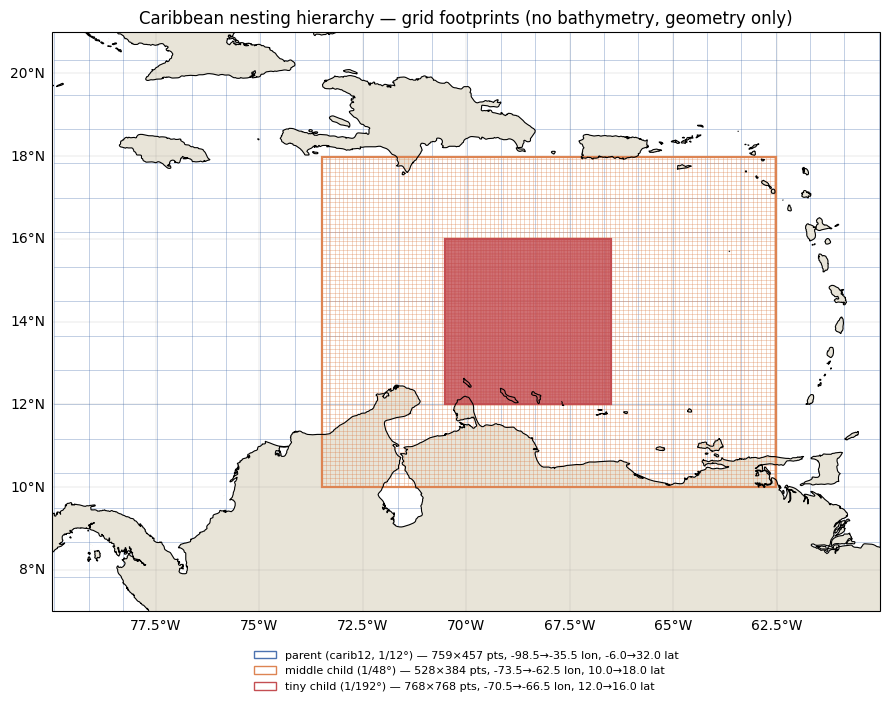

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import cartopy.crs as ccrs
import cartopy.feature as cfeature

GRIDS = {
    "parent (carib12, 1/12°)": (parent_grid, "#4C72B0", 10),
    "middle child (1/48°)": (mid_grid, "#DD8452", 5),
    "tiny child (1/192°)": (tiny_grid, "#C44E52", 2),
}

# crop the parent's huge basin-scale grid down to just the region around the nested children
LON_CROP = (-80.0, -60.0)
LAT_CROP = (7.0, 21.0)

def crop_mesh(lon2d, lat2d, lon_range, lat_range):
    in_box = (lon2d >= lon_range[0]) & (lon2d <= lon_range[1]) & (lat2d >= lat_range[0]) & (lat2d <= lat_range[1])
    rows = np.where(in_box.any(axis=1))[0]
    cols = np.where(in_box.any(axis=0))[0]
    if len(rows) == 0 or len(cols) == 0:
        return lon2d, lat2d
    r0, r1 = rows.min(), rows.max() + 1
    c0, c1 = cols.min(), cols.max() + 1
    return lon2d[r0:r1, c0:c1], lat2d[r0:r1, c0:c1]

def draw_mesh(ax, lon2d, lat2d, step, color, zorder):
    tf = ccrs.PlateCarree()
    ax.plot(lon2d[::step, :].T, lat2d[::step, :].T, color=color, linewidth=0.4, alpha=0.6, zorder=zorder, transform=tf)
    ax.plot(lon2d[:, ::step], lat2d[:, ::step], color=color, linewidth=0.4, alpha=0.6, zorder=zorder, transform=tf)

fig, ax = plt.subplots(figsize=(9, 7), subplot_kw={"projection": ccrs.PlateCarree()})
ax.add_feature(cfeature.LAND, facecolor="#e8e4d8", zorder=1)
ax.coastlines(resolution="10m", linewidth=0.8, zorder=20)

legend_handles = []
for i, (label, (grid, color, step)) in enumerate(GRIDS.items()):
    lon2d, lat2d = grid.tlon.values, grid.tlat.values
    if "parent" in label:
        lon2d, lat2d = crop_mesh(lon2d, lat2d, LON_CROP, LAT_CROP)
    z = i * 2
    draw_mesh(ax, lon2d, lat2d, step, color, zorder=z)
    lon0, lon1 = np.nanmin(grid.tlon.values), np.nanmax(grid.tlon.values)
    lat0, lat1 = np.nanmin(grid.tlat.values), np.nanmax(grid.tlat.values)
    ax.add_patch(mpatches.Rectangle((lon0, lat0), lon1 - lon0, lat1 - lat0,
                                     fill=False, edgecolor=color, linewidth=1.6, zorder=z + 1,
                                     transform=ccrs.PlateCarree()))
    ny, nx = grid.tlon.shape
    legend_handles.append(mpatches.Patch(edgecolor=color, facecolor="none",
                                          label=f"{label} — {nx}×{ny} pts, {lon0:.1f}→{lon1:.1f} lon, {lat0:.1f}→{lat1:.1f} lat"))

ax.set_extent([*LON_CROP, *LAT_CROP], crs=ccrs.PlateCarree())
gl = ax.gridlines(draw_labels=True, linewidth=0.3, color="gray", alpha=0.4, zorder=0)
gl.top_labels = False
gl.right_labels = False
ax.set_title("Caribbean nesting hierarchy — grid footprints (no bathymetry, geometry only)")
ax.legend(handles=legend_handles, loc="upper center", bbox_to_anchor=(0.5, -0.05), fontsize=8, frameon=False)
fig.tight_layout()
plt.show()


## Step 3 — Bathymetry / topography (parent, middle child, tiny child)

Parent topo depth range: 0.0 – 8318.5 m


**NOTE**
            If bathymetry setup fails (e.g. kernel crashes), restart the kernel and edit this cell.
            Call ``[topo_object_name].mpi_set_from_dataset()`` instead. Follow the given instructions for using mpi
            and ESMF_Regrid outside of a python environment. This breaks up the process, so be sure to call
            ``[topo_object_name].tidy_dataset() after regridding with mpi.
Slicing source bathymetry to domain: (-73.5, -62.5) x (10.0, 18.0) with buffer 0.5


Begin regridding dataset...

Original dataset size: 12.48 Mb
Regridded size: 6.49 Mb

Generating regridding weights using xESMF with method 'bilinear'...


Tidy bathymetry: Reading in regridded bathymetry to fix up metadata...done. Filling in inland lakes and channels... 

**NOTE**
            If bathymetry setup fails (e.g. kernel crashes), restart the kernel and edit this cell.
            Call ``[topo_object_name].mpi_set_from_dataset()`` instead. Follow the given instructions for using mpi
            and ESMF_Regrid outside of a python environment. This breaks up the process, so be sure to call
            ``[topo_object_name].tidy_dataset() after regridding with mpi.
Slicing source bathymetry to domain: (-70.5, -66.5) x (12.0, 16.0) with buffer 0.5


Begin regridding dataset...

Original dataset size: 2.90 Mb
Regridded size: 18.87 Mb

Generating regridding weights using xESMF with method 'bilinear'...


Tidy bathymetry: Reading in regridded bathymetry to fix up metadata...done. Filling in inland lakes and channels... 

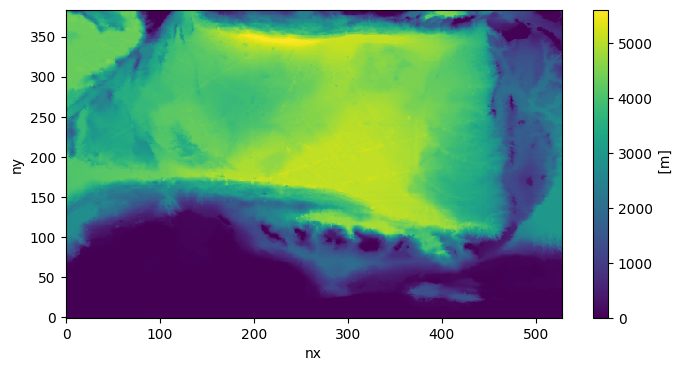

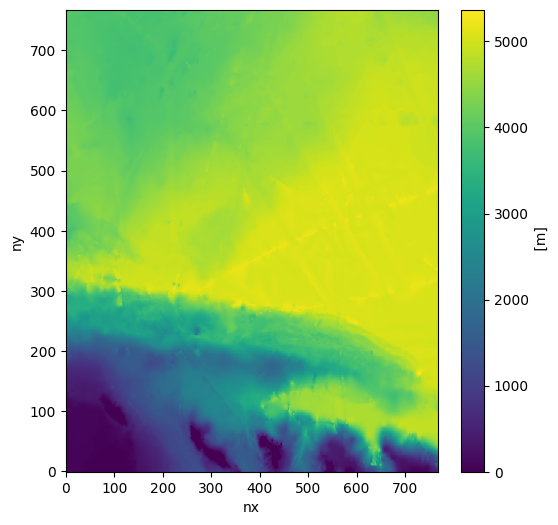

In [5]:
# Parent — load the existing topography; uses the same grid hash so it matches parent_grid
parent_topo = Topo.from_topo_file(
    grid           = parent_grid,
    topo_file_path = REF_TOPOG,
    min_depth      = 10.0,
    varname        = "depth",
    git            = False,
)
print(f"Parent topo depth range: {float(parent_topo.depth.min()):.1f} – {float(parent_topo.depth.max()):.1f} m")

# Middle child — from GEBCO
mid_topo = Topo(grid=mid_grid, min_depth=10.0)
mid_topo.set_from_dataset(
    bathymetry_path           = GEBCO,
    longitude_coordinate_name = "lon",
    latitude_coordinate_name  = "lat",
    vertical_coordinate_name  = "elevation",
)
mid_topo.depth.plot(figsize=(8, 4))

# Tiny child — from GEBCO
tiny_topo = Topo(grid=tiny_grid, min_depth=10.0)
tiny_topo.set_from_dataset(
    bathymetry_path           = GEBCO,
    longitude_coordinate_name = "lon",
    latitude_coordinate_name  = "lat",
    vertical_coordinate_name  = "elevation",
)
tiny_topo.depth.plot(figsize=(6, 6))


## Step 4 — Vertical grids (parent, middle child, tiny child)

In [6]:
# Parent — load the existing 65-level vertical grid
parent_vgrid = VGrid.from_file(str(REF_VGRID))

# Middle child — 40 levels, hyperbolic stretching
mid_vgrid = VGrid.hyperbolic(
    nk    = 40,
    depth = float(mid_topo.depth.max()),
    ratio = 10.0,
)

# Tiny child — 30 levels, hyperbolic stretching
tiny_vgrid = VGrid.hyperbolic(
    nk    = 30,
    depth = float(tiny_topo.depth.max()),
    ratio = 10.0,
)


## Step 5 — Create the CESM cases (parent, middle child, tiny child)

In [7]:
COMPSET = "1850_DATM%JRA_SLND_SICE_MOM6%REGIONAL_SROF_SGLC_SWAV"

# Parent already created and run — DO NOT re-run this cell. Kept only for reference/history.
# parent_case = Case(
#     cesmroot      = CESMROOT,
#     caseroot      = PARENT_CASE,
#     inputdir      = PARENT_INPUT,
#     compset       = COMPSET,
#     ocn_grid      = parent_grid,
#     ocn_topo      = parent_topo,
#     ocn_vgrid     = parent_vgrid,
#     machine       = "derecho",
#     project       = PROJECT,
#     override      = True,
# )


In [8]:
mid_case = Case(
    cesmroot      = CESMROOT,
    caseroot      = MID_CASE,
    inputdir      = MID_INPUT,
    compset       = COMPSET,
    ocn_grid      = mid_grid,
    ocn_topo      = mid_topo,
    ocn_vgrid     = mid_vgrid,
    machine       = "derecho",
    project       = PROJECT,
    override      = True,
)

tiny_case = Case(
    cesmroot      = CESMROOT,
    caseroot      = TINY_CASE,
    inputdir      = TINY_INPUT,
    compset       = COMPSET,
    ocn_grid      = tiny_grid,
    ocn_topo      = tiny_topo,
    ocn_vgrid     = tiny_vgrid,
    machine       = "derecho",
    project       = PROJECT,
    override      = True,
)


INFO:	initialize:Initializing the visualCaseGen system...


INFO:  csp_solver:CspSolver initialized.


Creating case...

• Updating ccs_config/modelgrid_aliases_nuopc.xml file to include the new resolution "carib_mid_child" consisting of the following component grids.
 atm grid: "TL319" 
 lnd grid: "TL319" 
 ocn grid: "carib_mid_child".
 rof grid: "null".

• Updating ccs_config/component_grids_nuopc.xml file to include newly generated ocean grid "carib_mid_child" with the following properties:
 nx: 528, ny: 384. ocean mesh: /glade/u/home/manishrv/scratch/croc_input/carib_mid_child/ocnice/ESMF_mesh_carib_mid_child_b48cd8.nc.

Running the create_newcase tool with the following command:

/glade/u/home/manishrv/work/installs/CROCESM_workshop_2025/cime/scripts/create_newcase --compset 1850_DATM%JRA_SLND_SICE_MOM6%REGIONAL_SROF_SGLC_SWAV --res carib_mid_child --case /glade/u/home/manishrv/croc_cases/carib_mid_child --machine derecho --run-unsupported --project ncgd0011 --non-local 



The create_newcase command was successful.

Navigating to the case directory:

cd /glade/u/home/manishrv/croc_cases/carib_mid_child

Running the case.setup script with the following command:

./case.setup --non-local



Adding parameter changes to user_nl_mom:

  ! Custom Horizonal Grid, Topography, and Vertical Grid
  INPUTDIR = /glade/u/home/manishrv/scratch/croc_input/carib_mid_child/ocnice
  TRIPOLAR_N = False
  REENTRANT_X = False
  REENTRANT_Y = False
  NIGLOBAL = 528
  NJGLOBAL = 384
  GRID_CONFIG = mosaic
  GRID_FILE = ocean_hgrid_carib_mid_child_b48cd8.nc
  TOPO_CONFIG = file
  TOPO_FILE = ocean_topog_carib_mid_child_b48cd8.nc
  MAXIMUM_DEPTH = 5600.0
  MINIMUM_DEPTH = 10.0
  NK = 40
  COORD_CONFIG = none
  ALE_COORDINATE_CONFIG = FILE:ocean_vgrid_carib_mid_child_b48cd8.nc
  REGRIDDING_COORDINATE_MODE = Z*

  ! Timesteps (based on grid resolution)
  DT = 150.0
  DT_THERM = 600.0



...

The create_newcase command was successful.

Navigating to the case directory:

cd /glade/u/home/manishrv/croc_cases/carib_tiny_child

Running the case.setup script with the following command:

./case.setup --non-local



Adding parameter changes to user_nl_mom:

  ! Custom Horizonal Grid, Topography, and Vertical Grid
  INPUTDIR = /glade/u/home/manishrv/scratch/croc_input/carib_tiny_child/ocnice
  TRIPOLAR_N = False
  REENTRANT_X = False
  REENTRANT_Y = False
  NIGLOBAL = 768
  NJGLOBAL = 768
  GRID_CONFIG = mosaic
  GRID_FILE = ocean_hgrid_carib_tiny_child_c59e5e.nc
  TOPO_CONFIG = file
  TOPO_FILE = ocean_topog_carib_tiny_child_c59e5e.nc
  MAXIMUM_DEPTH = 5368.0
  MINIMUM_DEPTH = 10.0
  NK = 30
  COORD_CONFIG = none
  ALE_COORDINATE_CONFIG = FILE:ocean_vgrid_carib_tiny_child_c59e5e.nc
  REGRIDDING_COORDINATE_MODE = Z*

  ! Timesteps (based on grid resolution)
  DT = 25.0
  DT_THERM = 100.0



INFO:	stage:SUCCESS: All stages are complete.


Case created successfully at /glade/u/home/manishrv/croc_cases/carib_tiny_child.

To further customize, build, and run the case, navigate to the case directory in your terminal. To create another case, restart the notebook.



./xmlchange MOM6_MEMORY_MODE=dynamic_symmetric --non-local



### DATM JRA stream years

The `DATM%JRA` compset's default `datm.streams.xml` doesn't necessarily line up with this demo's
`RUN_STARTDATE=2000-01-01` — the JRA55 atmospheric forcing streams (`CORE_IAF_JRA.*`) need their
`year_first`/`year_last`/`year_align`/`datafiles` overridden to point at the 1999-2000 JRA files so
the DATM cycles the correct years. This has to be applied to **every** case's `user_nl_datm_streams`
(re-creating a case with `override=True` resets this file back to the default template), not just
the parent — easy to miss since the case still builds fine without it, it just cycles the wrong
forcing years at runtime.


In [9]:
import shutil

DATM_STREAMS_OVERRIDE = Path("~/documents/croc/dev/user_nl_datm_streams_jra_1999_2000").expanduser()

# Parent already has this override applied — only re-apply for the recreated child cases.
for case in (mid_case, tiny_case):
    shutil.copy(DATM_STREAMS_OVERRIDE, case.caseroot / "user_nl_datm_streams")
    print(f"applied JRA 1999-2000 stream override to {case.caseroot}")


applied JRA 1999-2000 stream override to /glade/u/home/manishrv/croc_cases/carib_mid_child
applied JRA 1999-2000 stream override to /glade/u/home/manishrv/croc_cases/carib_tiny_child


## Step 6 — Configure forcings (parent, middle child, tiny child)

The parent reuses Ajanney's existing OBC files (GLORYS-derived). Both children instead
read their **parent's** nesting output as OBCs, via `CESM_MOM_OUTPUT.get_mom6_output_data`.

> **Note**: `CESM_MOM_OUTPUT` (`CrocoDash/raw_data_access/datasets/cesm_ocean_output.py`)
> is a dedicated product for native MOM6 output, with MOM6-native variable/coordinate
> metadata (`thetao`/`so`/`uo`/`vo`/`zos` on `xh`/`yh`/`xq`/`yq`/`z_l`) — split out from
> the CESM-POP-oriented `CESM_POP_OUTPUT` product so the two don't share a mismatched
> metadata set. It has two access methods: `get_mom6_output_data` (multi-variable-per-
> file history/diag_table output, used below) and `get_mom6_single_variable_data` (if a
> parent run's output is instead organized in the CESM single-variable-per-file/tseries
> convention). `CESM_MOM_OUTPUT` has no universal default `dataset_path` (it's meant to
> point at any user-supplied directory) — each child passes its own parent's nesting
> output directory in via `function_overrides={"dataset_path": ...}`
> (`raw_data_access_flexible_default_args`), instead of hand-editing `config.json`
> between `configure_forcings()` and `process_forcings()`.

In [10]:
from ProConPy.config_var import cvars

MID_DATES    = ["2000-01-01 00:00:00", "2000-02-01 00:00:00"]
TINY_DATES   = ["2000-01-01 00:00:00", "2000-02-01 00:00:00"]

# NOTE: Case.configure_forcings() writes to user_nl_mom via a global cvars["CASEROOT"]
# singleton that is only set when a Case object is *constructed* (see case.py) -- it is
# never re-synced inside configure_forcings() itself. With both child cases already built
# in Step 5, cvars["CASEROOT"] is left pointing at whichever case was created *last*
# (tiny_case), so calling configure_forcings() on mid_case without resetting it first
# would silently write its OBC/IC config into tiny_case's user_nl_mom instead.
# Reset it explicitly before each call until this is fixed upstream in CrocoDash.

# Parent already configured and run — not re-run here.

# dataset_path is CESM_MOM_OUTPUT's one non-required arg with no universal default (it's
# meant to point at any user-supplied directory), so it's passed per-call via
# function_overrides (added in raw_data_access_flexible_default_args) instead of being
# hand-edited into config.json between configure_forcings() and process_forcings().
# function_overrides gets written straight to config.json, so it must be JSON-serializable
# (plain str), not a Path.
cvars["CASEROOT"].value = mid_case.caseroot.as_posix()
mid_case.configure_forcings(
    date_range        = MID_DATES,
    product_name      = "cesm_mom_output",
    function_name     = "get_mom6_output_data",
    function_overrides = {"dataset_path": PARENT_NESTING_OUTPUT.as_posix()},
)

cvars["CASEROOT"].value = tiny_case.caseroot.as_posix()
tiny_case.configure_forcings(
    date_range        = TINY_DATES,
    product_name      = "cesm_mom_output",
    function_name     = "get_mom6_output_data",
    function_overrides = {"dataset_path": MID_NESTING_OUTPUT.as_posix()},
)


INFO:CrocoDash.forcing_configurations.base:[SKIP] tides missing args: ['tpxo_elevation_filepath', 'tpxo_velocity_filepath', 'tidal_constituents']


INFO:CrocoDash.forcing_configurations.base:[SKIP] BGC incompatible with compset


INFO:CrocoDash.forcing_configurations.base:[SKIP] CICE incompatible with compset


INFO:CrocoDash.forcing_configurations.base:[SKIP] BGCIC incompatible with compset


INFO:CrocoDash.forcing_configurations.base:[SKIP] BGCIronForcing incompatible with compset


...

INFO:CrocoDash.forcing_configurations.base:[SKIP] Runoff incompatible with compset


INFO:CrocoDash.forcing_configurations.base:[SKIP] Chl missing args: ['chl_processed_filepath']


Adding parameter changes to user_nl_mom:

  ! Initial conditions
  INIT_LAYERS_FROM_Z_FILE = True
  Z_INIT_ALE_REMAPPING = True
  TEMP_SALT_INIT_VERTICAL_REMAP_ONLY = True
  DEPRESS_INITIAL_SURFACE = True
  VELOCITY_CONFIG = file
  TEMP_SALT_Z_INIT_FILE = init_tracers.nc
  SURFACE_HEIGHT_IC_FILE = init_eta.nc
  VELOCITY_FILE = init_vel.nc
  Z_INIT_FILE_PTEMP_VAR = temp
  Z_INIT_FILE_SALT_VAR = salt
  SURFACE_HEIGHT_IC_VAR = eta_t
  U_IC_VAR = u
  V_IC_VAR = v

  ! Open boundary conditions
  OBC_NUMBER_OF_SEGMENTS = 4
  OBC_FREESLIP_VORTICITY = False
  OBC_FREESLIP_STRAIN = False
  OBC_COMPUTED_VORTICITY = True
  OBC_COMPUTED_STRAIN = True
  OBC_ZERO_BIHARMONIC = True
  OBC_TRACER_RESERVOIR_LENGTH_SCALE_OUT = 3.0E+04
  OBC_TRACER_RESERVOIR_LENGTH_SCALE_IN = 3000.0
  BRUSHCUTTER_MODE = True
  OBC_SEGMENT_001 = "J=0,I=0:N,FLATHER,ORLANSKI,NUDGED,ORLANSKI_TAN,NUDGED_TAN"
  OBC_SEGMENT_001_VELOCITY_NUDGING_TIMESCALES = 0.3, 360.0
  OBC_SEGMENT_001_DATA = "U=file:forcing_obc_segment_001.nc(u

./xmlchange STOP_OPTION=ndays --non-local



./xmlchange STOP_N=31 --non-local



---
## Summary

This notebook walked through a full 3-level nesting hierarchy, building all three domains together at each step:

| Domain | Resolution | lon | lat | OBC source |
|--------|-----------|-----|-----|------------|
| Parent (carib12) | 1/12° | -98.5→-35.5 | -6→32 | GLORYS / Ajanney OBC files |
| Middle child | 1/48° | -73.5→-62.5 | 10→18 | Parent nesting output |
| Tiny child | 1/192° | -70.5→-66.5 | 12→16 | Middle-child nesting output |

Each level runs independently once its case is built. Once the parent finishes, the middle child can start;  
once the middle child finishes, the tiny child can start.

See `CESM_MOM_OUTPUT` (`CrocoDash/raw_data_access/datasets/cesm_ocean_output.py`) for the
native-MOM6-output readers used above — `get_mom6_output_data` (multi-variable-per-file
history/diag_table output) and `get_mom6_single_variable_data` (CESM tseries-style
output) — and their docstrings for direct-call usage. `CESM_MOM_OUTPUT` is a separate
product from `CESM_POP_OUTPUT` specifically because they need different variable/
coordinate metadata (native MOM6 names vs. CESM-POP names). Each child's `dataset_path`
is threaded through per-call via `configure_forcings(function_overrides={"dataset_path": ...})`
rather than sourced from class-level metadata, since `CESM_MOM_OUTPUT` has no single
universal default (it's meant to point at whichever parent run produced its OBC source).